1. Загрузите изображение.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
path = "color_img.jpg"
img = cv2.imread(path)

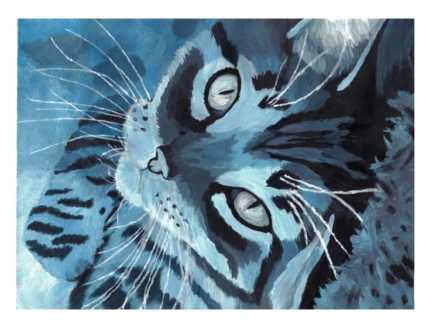

In [3]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

3. Бинаризуйте исходное изображение.

In [4]:
def mono2binary(array: np.ndarray, threshold = 0.5):
    boundary = threshold * (np.iinfo(np.uint8).max - np.iinfo(np.uint8).min)
    binary = (array > boundary).astype(np.uint8)
    return binary

In [5]:
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_binary = mono2binary(img_gray)

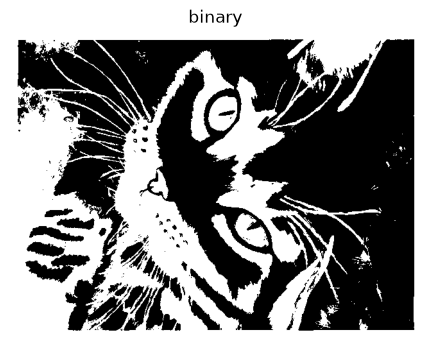

In [6]:
plt.figure(figsize=(6, 4))
plt.imshow(img_binary, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("binary")
plt.show()

2 - Разбейте изображение на блоки (например, 16*16)

4 - Преобразуйте изображение: выполните развертку изображения по блокам, закодировав каждый 0 или 1 ( в зависимости от распределения черных/белых пикселей внутри блока).

In [18]:
from math import ceil

In [42]:
def block_conv(array: np.ndarray, block_size: int) -> np.ndarray:
    h, w = array.shape
    h_new, w_new = ceil(h / block_size), ceil(w / block_size)

    new_array = np.zeros((h_new, w_new), dtype=np.uint8)
    for i in range(0, h, block_size):
        dh = min(block_size, h-i)
        for j in range(0, w, block_size):
            dw = min(block_size, w-j)

            flag = np.mean(array[i:i+dh, j:j+dw]) > 0.5
            pixel = flag * 1
            new_array[i//block_size,j//block_size] = pixel

    return new_array

In [43]:
block_size = 16

In [44]:
img_blocked = block_conv(img_binary, block_size)

In [45]:
print(img_binary.shape)
print(img_blocked.shape)

(480, 640)
(30, 40)


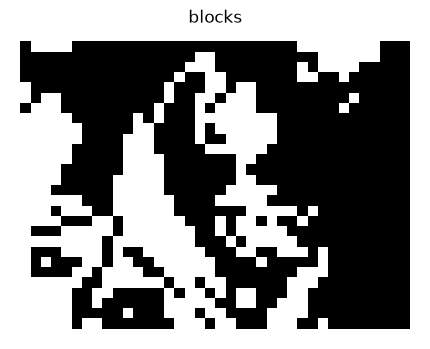

In [53]:
plt.figure(figsize=(6, 4))
plt.imshow(img_blocked, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("blocks")
plt.show()

In [47]:
print(np.unique(img_blocked))

[0 1]


5. Далее используете развертку исходного изображения (по строкам или столбцам).

In [49]:
img_flattened = img_blocked.flatten()
print(img_flattened)

[1 1 1 ... 1 1 1]


6. Преобразованные данные постройте кодирование исходного сгенерированного изображения в виде r’00001001...00000’. Длина символьной строки – количество патчей исходного изображения. (Исходное изображение разбивается на патчи, размер патча p x p, количество патчей n // p x m // p, патчи не пересекаются).

In [51]:
h, w = img_blocked.shape

In [52]:
code_str = ''.join(map(str, img_flattened))
print(code_str)

1111111111111111111111111111111111111111101111000000000000000000000011111111000110000000000000000011000000000011111100011000000000000000011100000000101111000001100000000000000010011000000011001000000111000000000000010001101100000000000000011101100000000001001101110000000001000001101110000000001000101111000000001000000111111100000010100011111111000000000000011111111000001100001011111100000000000001111111100001110000100111110000000000000111111100000111000001111110000000000000011111110000011110000000110000000000000001111110000001111000000010000000000000000111111000001111100000001100000000000000011111000000111110000001111100000000000001111111100011111100001111100000000000000111110111001111110000000111110100000000011111100011011111100010110100100000000001110001111101111111001011111000000000000111111111101111111100010111110000000000011100011110100111111000110011101000000001110100011011001111110000100000100000000111000011011110011111000000001110000000011111111001111110110110000001110000000001

7. Используя регулярные строки, найдите количество паттернов вида "крест" на блоках исходного изображения.
* Паттерн вида "крест":
[1, 0, 1]
[0, 0, 0]
[1, 0, 1]

In [55]:
import re

In [59]:
result = re.findall(rf"(?=(101.{{{w-3}}}000.{{{w-3}}}101))", code_str)

In [60]:
print(len(result))

0


In [63]:
example_str = "000101111111000000000101111"
result = re.findall(rf"(?=(101.{{{9-3}}}000.{{{9-3}}}101))", example_str)
print(len(result))

1
